In [1]:
from sklearn.datasets import load_wine

data = load_wine(as_frame=True)

df = data.frame

df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [4]:
x = df.drop("target", axis=1)

y = df["target"]

In [6]:
print(x.shape)
print(x.isnull().sum())
print(x.duplicated().sum())
x.describe()

(178, 13)
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64
0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


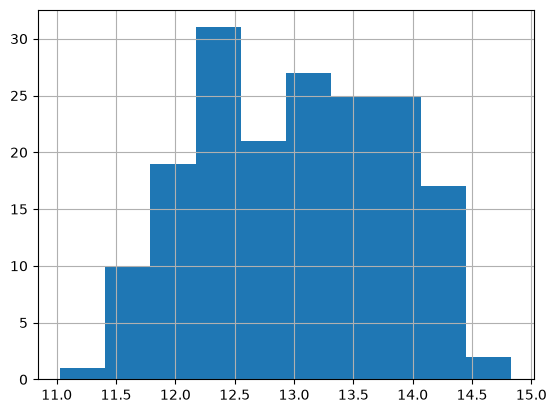

In [7]:
import matplotlib.pyplot as plt

x["alcohol"].hist()

plt.show()

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_scaled = scaler.fit_transform(x)

In [10]:
from sklearn.cluster import KMeans

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(x_scaled)
    print(k, model.inertia_)

1 2314.0000000000005
2 1661.6761165626508
3 1277.9284888446423
4 1211.7531134671585
5 1123.1565470796963
6 1079.5385091588262
7 1014.4309086924652
8 982.6549762937699
9 927.9560760726213
10 879.4257007542496


In [11]:
from sklearn.metrics import silhouette_score

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42)
    labels = model.fit_predict(x_scaled)
    score = silhouette_score(x_scaled, labels)
    print(k, score)

2 0.2650328591008738
3 0.2848589191898987
4 0.25422758316007776
5 0.1836210510769814
6 0.16899191019013057
7 0.17260155610949213
8 0.16250411307671145
9 0.17387393345450863
10 0.13956723664297552


In [12]:
model = KMeans(n_clusters=3, random_state=42)

labels = model.fit_predict(x_scaled)

In [13]:
import pandas as pd

print(pd.Series(labels).value_counts())

0    65
2    62
1    51
Name: count, dtype: int64


In [14]:
x_result = x.copy()
x_result["cluster"] = labels

print(x_result.groupby("cluster").mean())

           alcohol  malic_acid       ash  alcalinity_of_ash   magnesium  \
cluster                                                                   
0        12.250923    1.897385  2.231231          20.063077   92.738462   
1        13.134118    3.307255  2.417647          21.241176   98.666667   
2        13.676774    1.997903  2.466290          17.462903  107.967742   

         total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
cluster                                                                     
0             2.247692    2.050000              0.357692         1.624154   
1             1.683922    0.818824              0.451961         1.145882   
2             2.847581    3.003226              0.292097         1.922097   

         color_intensity       hue  od280/od315_of_diluted_wines      proline  
cluster                                                                        
0               2.973077  1.062708                      2.803385   510.169231 

In [15]:
from sklearn.cluster import DBSCAN

model_db = DBSCAN(eps=2, min_samples=5)
labels_db = model_db.fit_predict(x_scaled)

print(pd.Series(labels_db).value_counts())

-1    85
 0    66
 4     9
 1     8
 2     5
 3     5
Name: count, dtype: int64


In [16]:
for e in [0.5, 1, 1.5, 2, 2.5, 3]:
    model_db = DBSCAN(eps=e, min_samples=5)
    labels_db = model_db.fit_predict(x_scaled)

    print("eps:", e)
    print("clusters:", len(set(labels_db)) - (1 if -1 in labels_db else 0))
    print("noise:", list(labels_db).count(-1))
    print()

eps: 0.5
clusters: 0
noise: 178

eps: 1
clusters: 0
noise: 178

eps: 1.5
clusters: 0
noise: 178

eps: 2
clusters: 5
noise: 85

eps: 2.5
clusters: 1
noise: 24

eps: 3
clusters: 1
noise: 11



In [17]:
from sklearn.metrics import adjusted_rand_score

score_kmeans = adjusted_rand_score(y, labels)
score_dbscan = adjusted_rand_score(y, labels_db)

print("K-Means:", score_kmeans)
print("DBSCAN:", score_dbscan)

K-Means: 0.8974949815093207
DBSCAN: -0.005929398352149316
